# Qwen3-30B-A3B — TorchAO training throughput

One A100 40GB (physical GPU 2). GPTQ INT4 weights repacked for TorchAO's fused Triton forward/input-gradient kernels; FP16 compute, FP32 LoRA, rank 16 on layers 45–47 (attention + experts). Same model loader and adapters as `qlora-Qwen3-30B-A3B_torchao.ipynb`. No pruning, checkpointing, or TransformerLens wrappers.

Each configuration resets adapters and SGD state, runs two warmup steps and three measured steps, reusing its fixed input batch. Fixed-length blocks of real WikiText, no padding. These are throughput measurements, not a quality experiment. Unlike the previous variable-length dataset, each sample has exactly the stated context length.

The phase timings synchronize CUDA and include CPU/launch overhead. Full step includes forward + causal loss, scaled backward, gradient clipping and SGD update; excludes dataloading, zero_grad, model loading and profiling. Three samples give a quick estimate, not a statistical confidence interval. The early frozen layers do not need backward when no input requires gradients.

Re-run from repository root: `CUDA_VISIBLE_DEVICES=2 COMPUTE_DTYPE=fp16 .venv/bin/python -u experiments/qlora/slop_experiments/benchmark_qwen_torchao.py --batches 1 2 4 8 16`

Batch 16 was measured in a separate process with the same setup and appended to the original batch 1/2/4/8 results. Batch 16 × context 512 ran out of memory; its empty cells are not zero throughput. Raw additional results are in `5_speed_vs_batch_size/torchao_training_benchmark/bs16/`.

Opening/executing this report only reads results; it does not load the model.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image, FileLink

root = Path.cwd()
while not (root / 'lora_transfer_pruning').exists():
    if (root / 'LoRa-Transfer-Pruning').exists():
        root = root / 'LoRa-Transfer-Pruning'
        break
    if root == root.parent:
        raise RuntimeError('Cannot find repository')
    root = root.parent
results = root / 'experiments/qlora/slop_experiments/5_speed_vs_batch_size/torchao_training_benchmark'
report = json.loads((results / 'benchmark.json').read_text())
df = pd.DataFrame(report['results'])
display(report['setup'])
display(df.drop(columns=['steps', 'warmup'], errors='ignore').round(3))

{'checkpoint': 'Qwen/Qwen3-30B-A3B-GPTQ-Int4',
 'revision': '9b534e4318b7ebc3c961a839f13eb18b1833f441',
 'dtype': 'torch.float16',
 'gpu': 'NVIDIA A100-PCIE-40GB',
 'physical_gpu': '2',
 'torch': '2.10.0+cu128',
 'lora_layers': [45, 46, 47],
 'lora_rank': 16,
 'trainable_parameters': 52740096,
 'optimizer': 'SGD lr=3e-4 momentum=.9 nesterov, clip=1, AMP GradScaler',
 'gradient_checkpointing': False,
 'attention': 'sdpa',
 'warmup_steps': 2,
 'measured_steps': 3,
 'cpu_threads': 4,
 'input': 'Packed WikiText validation text; exact B*S tokens, no padding. Same prefixes per row.',
 'measurement': 'Median of synchronized wall times. Excludes zero_grad, dataloading, reset, profiling. Includes forward/loss, scaled backward, clip/optimizer. No Trainer overhead.',
 'kernel': {'BLOCK_M': 64, 'BLOCK_N': 128, 'BLOCK_K': 64, 'SPLIT_K': 1},
 'additional_runs': [{'file': 'bs16/benchmark.json',
   'batch_size': 16,
   'note': 'Separate process, same settings. First eight input rows unchanged.'}]}

,batch_size,context_length,status,forward_s,backward_s,optimizer_s,step_s,step_min_s,step_max_s,fwd_bwd_s,samples_per_s,input_tokens_per_s,loss_tokens_per_s,peak_allocated_GiB,peak_reserved_GiB,skipped_measured_updates,error
0,1,64,OK,2.693,0.364,0.090,3.147,3.122,3.153,3.057,0.318,20.339,20.021,16.492,19.750,0.0,NaN
1,2,64,OK,3.144,0.420,0.093,3.660,3.646,3.752,3.568,0.546,34.972,34.426,16.667,19.891,0.0,NaN
2,4,64,OK,3.578,0.478,0.096,4.154,4.143,4.207,4.058,0.963,61.626,60.663,16.995,20.168,0.0,NaN
3,8,64,OK,4.128,0.595,0.102,4.825,4.730,4.845,4.723,1.658,106.108,104.450,17.648,20.773,0.0,NaN
4,16,64,OK,4.457,0.533,0.099,5.096,4.944,5.186,4.997,3.140,200.950,197.810,18.904,22.119,0.0,NaN
5,1,128,OK,3.351,0.462,0.099,3.913,3.849,3.919,3.816,0.256,32.709,32.454,16.675,19.891,0.0,NaN
6,2,128,OK,3.653,0.521,0.100,4.280,4.239,4.339,4.182,0.467,59.815,59.348,17.007,20.164,0.0,NaN
7,4,128,OK,3.882,0.555,0.099,4.530,4.527,4.547,4.431,0.883,113.028,112.145,17.640,20.797,0.0,NaN
8,8,128,OK,4.253,0.588,0.102,4.946,4.932,5.009,4.847,1.617,207.017,205.400,18.900,22.143,0.0,NaN
9,16,128,OK,4.712,0.527,0.103,5.339,5.314,5.373,5.236,2.997,383.560,380.564,21.403,24.973,0.0,NaN


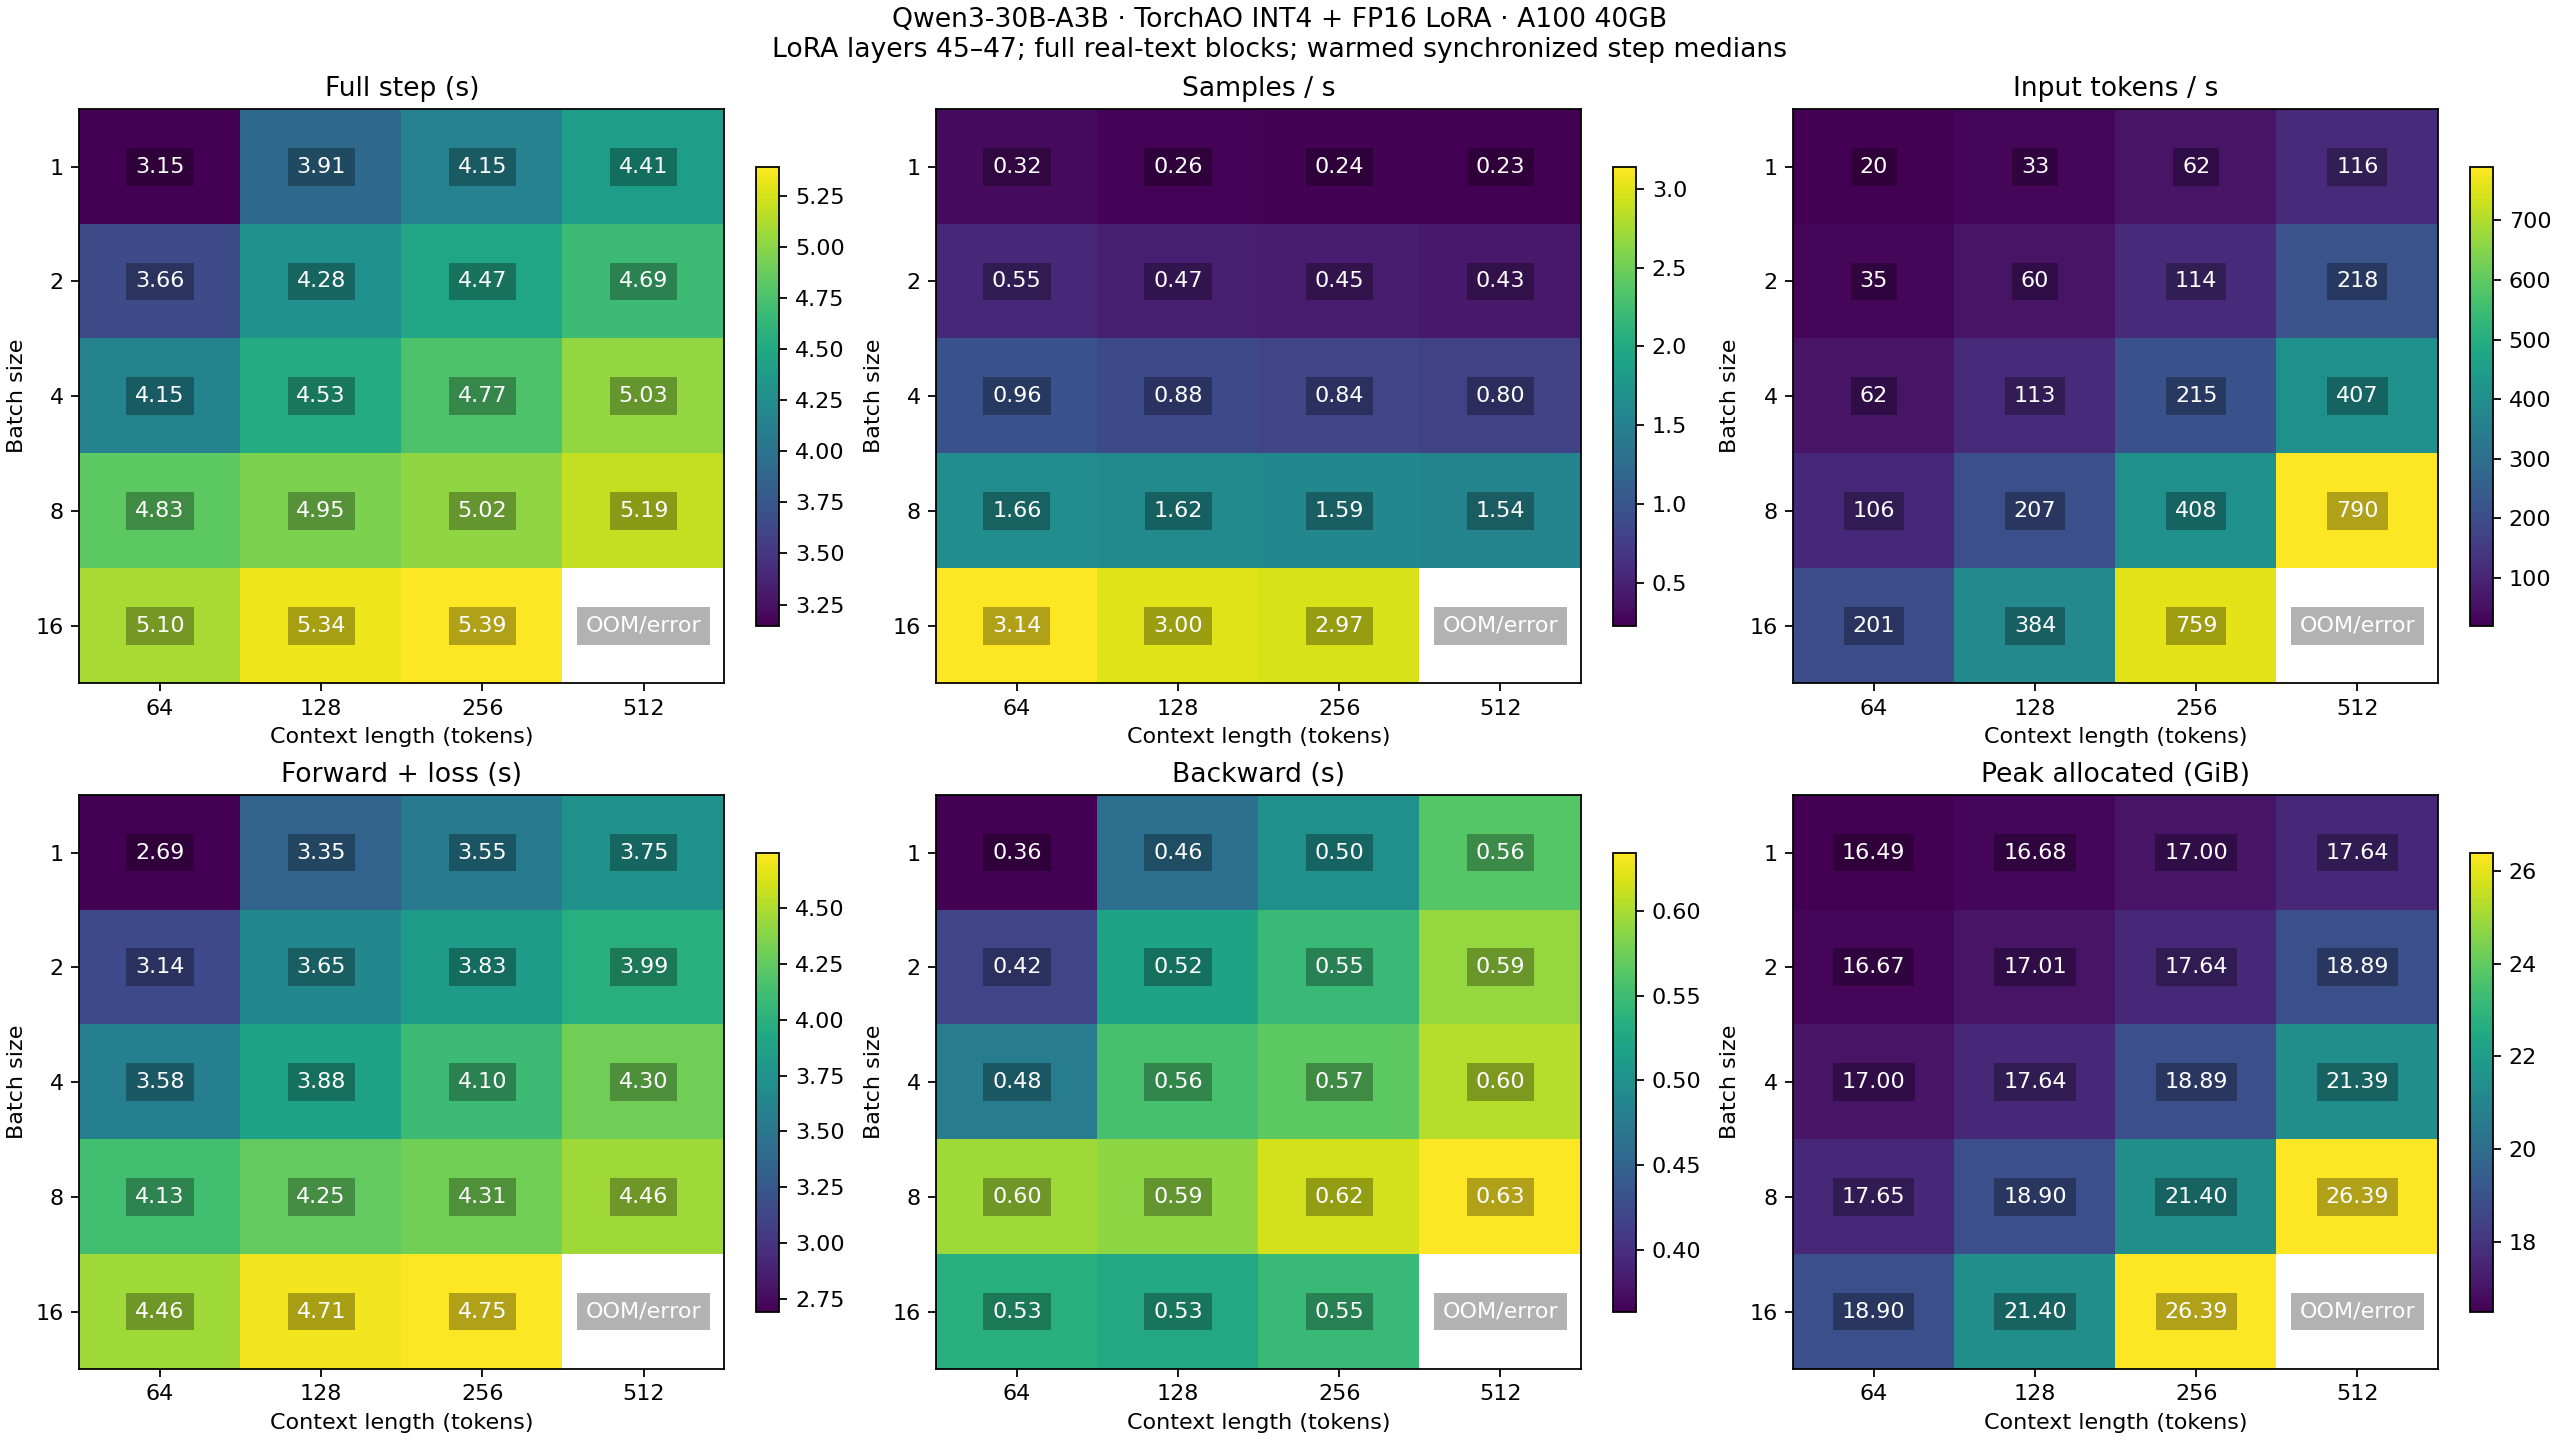

fwd_bwd_s


context_length,64,128,256,512
batch_size,,,,
1,3.057,3.816,4.049,4.312
2,3.568,4.182,4.373,4.581
4,4.058,4.431,4.665,4.907
8,4.723,4.847,4.924,5.083
16,4.997,5.236,5.297,NaN


step_s


context_length,64,128,256,512
batch_size,,,,
1,3.147,3.913,4.146,4.409
2,3.660,4.280,4.473,4.687
4,4.154,4.530,4.768,5.029
8,4.825,4.946,5.024,5.186
16,5.096,5.339,5.393,NaN


samples_per_s


context_length,64,128,256,512
batch_size,,,,
1,0.318,0.256,0.241,0.227
2,0.546,0.467,0.447,0.427
4,0.963,0.883,0.839,0.795
8,1.658,1.617,1.592,1.543
16,3.140,2.997,2.967,NaN


input_tokens_per_s


context_length,64,128,256,512
batch_size,,,,
1,20.339,32.709,61.743,116.113
2,34.972,59.815,114.471,218.476
4,61.626,113.028,214.785,407.250
8,106.108,207.017,407.620,789.777
16,200.950,383.560,759.479,NaN


peak_allocated_GiB


context_length,64,128,256,512
batch_size,,,,
1,16.492,16.675,17.004,17.638
2,16.667,17.007,17.641,18.894
4,16.995,17.640,18.892,21.391
8,17.648,18.900,21.399,26.388
16,18.904,21.403,26.395,NaN


In [2]:
display(Image(filename=str(results / 'batch_context_matrix.png')))
for metric in ['fwd_bwd_s', 'step_s', 'samples_per_s', 'input_tokens_per_s', 'peak_allocated_GiB']:
    print(metric)
    display(df.pivot(index='batch_size', columns='context_length', values=metric).round(3))

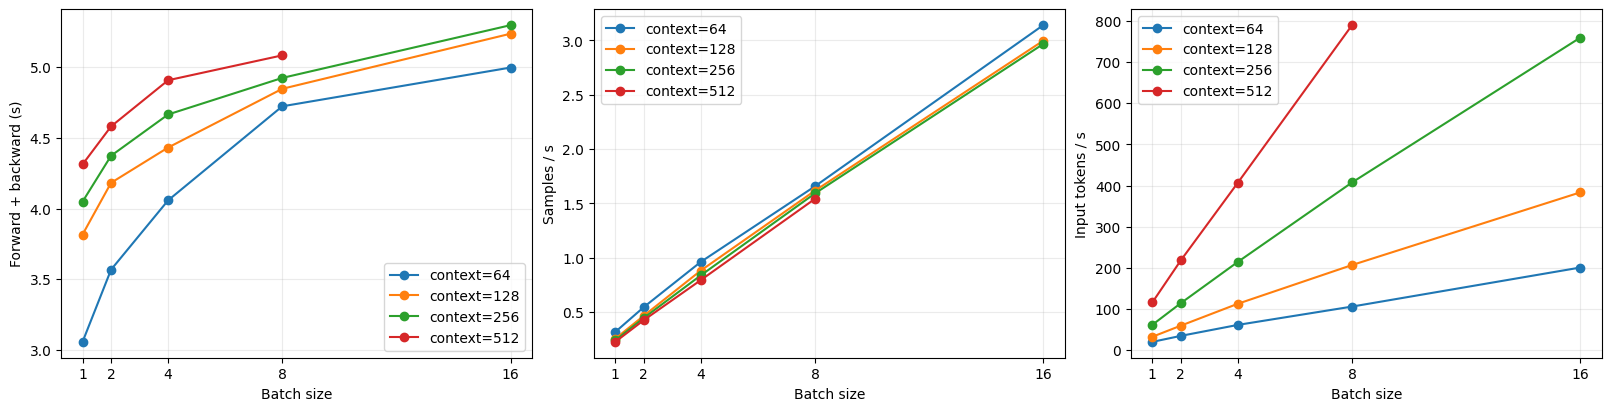

In [3]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for context, rows in df[df.status == 'OK'].groupby('context_length'):
    rows = rows.sort_values('batch_size')
    for ax, metric, title in zip(axes, ['fwd_bwd_s', 'samples_per_s', 'input_tokens_per_s'],
                                 ['Forward + backward (s)', 'Samples / s', 'Input tokens / s']):
        ax.plot(rows.batch_size, rows[metric], marker='o', label=f'context={context}')
        ax.set(xlabel='Batch size', ylabel=title, xticks=sorted(df.batch_size.unique()))
        ax.grid(alpha=.25)
        ax.legend()
plt.show()

## One-step Chrome trace

Start with `training_b8_s128.compact.chrome.json` in `chrome://tracing` or https://ui.perfetto.dev: GPU kernels, memory copies, long synchronizations and CPU phase labels. The full `training_b8_s128.chrome.json` additionally contains the PyTorch operator tree; `.json.gz` files are compressed copies. Search for `train.forward_and_loss`, `train.backward`, `train.clip_and_optimizer`. The trace is one warmed-up step, but profiler instrumentation slows it down: use the unprofiled matrix for absolute speed.

Tables below aggregate operators. Inclusive totals overlap parent/child operations: do not sum them. Self CPU time includes time inside blocking CUDA APIs, so it is not purely Python computation. GPU kernel durations and gaps are visible in the trace.

In [4]:
ops = pd.DataFrame(json.loads((results / 'profile_operators.json').read_text()))
display(ops[ops.name.str.startswith('train.')].round(3))
print('Top self CPU time')
display(ops.nlargest(20, 'self_cpu_ms').round(3))
print('Top self CUDA time')
display(ops.nlargest(20, 'self_device_ms').round(3))
summary = json.loads((results / 'profile_summary.json').read_text())
print('CUDA kernels per step:', summary['kernel_count'])
print('Sum of kernel durations (ms):', summary['sum_kernel_ms'])
display(pd.DataFrame(summary['kernels']).head(15))
display(FileLink(str(results / 'training_b8_s128.compact.chrome.json')))
display(FileLink(str(results / 'training_b8_s128.chrome.json')))
display(FileLink(str(results / 'training_b8_s128.chrome.json.gz')))

,name,calls,self_cpu_ms,cpu_total_ms,self_device_ms,device_total_ms
3,train.forward_and_loss,1,962.036,5045.051,0.000,1618.499
14,train.forward_and_loss,1,0.000,0.000,5051.371,5051.371
175,train.backward,1,792.103,796.498,0.000,0.006
176,train.backward,1,0.000,0.000,0.081,0.081
313,train.clip_and_optimizer,1,80.030,103.337,0.000,4.693
314,train.clip_and_optimizer,1,0.000,0.000,103.217,103.217


Top self CPU time


,name,calls,self_cpu_ms,cpu_total_ms,self_device_ms,device_total_ms
60,_Int4Matmul,15573,1921.189,2270.157,1145.860,1146.032
3,train.forward_and_loss,1,962.036,5045.051,0.000,1618.499
175,train.backward,1,792.103,796.498,0.000,0.006
13,cudaLaunchKernel,85329,522.290,535.897,0.000,0.080
104,aten::nonzero,5175,215.516,652.099,139.587,168.074
124,aten::index,10254,189.669,307.353,59.489,59.516
45,aten::mul,14824,184.638,283.559,85.025,85.036
61,cuLaunchKernelEx,16473,147.483,147.483,0.000,0.000
78,aten::mm,5468,138.067,178.508,58.539,58.539
8,aten::empty,24600,132.912,132.912,0.000,0.000


Top self CUDA time


,name,calls,self_cpu_ms,cpu_total_ms,self_device_ms,device_total_ms
14,train.forward_and_loss,1,0.000,0.000,5051.371,5051.371
62,_mixed_mm_kernel,16473,0.000,0.000,1216.550,1216.550
60,_Int4Matmul,15573,1921.189,2270.157,1145.860,1146.032
104,aten::nonzero,5175,215.516,652.099,139.587,168.074
314,train.clip_and_optimizer,1,0.000,0.000,103.217,103.217
45,aten::mul,14824,184.638,283.559,85.025,85.036
24,aten::copy_,12899,95.423,180.455,78.896,78.901
129,aten::index_add_,5127,55.828,88.200,73.819,73.819
230,_Int4MatmulBackward,900,131.299,153.681,70.690,70.690
124,aten::index,10254,189.669,307.353,59.489,59.516


CUDA kernels per step: 106535
Sum of kernel durations (ms): 1799.3236440000371


,kernel,calls,total_ms,median_us
0,_mixed_mm_kernel,16473,1216.549535,86.561
1,"void at::native::elementwise_kernel<128, 4, at...",5833,47.082316,7.104
2,void at::native::indexFuncLargeIndex<c10::Half...,3518,46.873141,11.648
3,"void at::native::index_elementwise_kernel<128,...",5520,36.883265,6.080
4,void at::native::(anonymous namespace)::write_...,5127,36.878458,7.200
5,void at_cuda_detail::cub::DeviceSelectSweepKer...,5175,36.751634,7.199
6,void at::native::unrolled_elementwise_kernel<a...,3820,32.162705,7.232
7,"void at::native::elementwise_kernel<128, 2, at...",5129,28.221209,5.376
8,void at::native::indexFuncSmallIndex<c10::Half...,1609,26.945531,13.792
9,void at_cuda_detail::cub::DeviceReduceKernel<a...,5127,24.962657,4.928


/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_training_benchmark/training_b8_s128.compact.chrome.json

/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_training_benchmark/training_b8_s128.chrome.json

/glazkov-dev/LoRa-Transfer-Pruning/experiments/qlora/results/torchao_training_benchmark/training_b8_s128.chrome.json.gz